# Circuit extraction: resource estimates before and after the update
Compares the machine resources requested by the circuit extraction estimator with the old and the new formulas, for the re-extraction benchmarks (nbS1, nbS1-O1, nbS1-HEX0, rCA1, rCA1 cylinder) and for sweeps over the extracted size.

| | Old | New |
| --- | --- | --- |
| Memory | `1 + 55e-6 * input neurons` | `1.2 * min(24, 2 + 0.04e-6 * input synapses)` |
| Time limit | `ceil(5e-6 * input neurons)` | `ceil(1 + 2 * (0.4e-9 * input synapses + 10.5e-9 * output synapses))`, rejected above 24 h |
| Disk | `1 + 1.85e-7 * output synapses` | `1 + 3.9e-7 * output synapses`, in steps of 50 GB |

The new estimates come from the real `estimate_task_resources` of this checkout (with mocked circuit metrics). The old ones are re-implemented here, with the same machine and disk limits.

Run this notebook with a kernel that uses this checkout's `.venv` (e.g. `obi-one-dev`).

In [1]:
import math
from collections import namedtuple
import sys
from pathlib import Path
from types import SimpleNamespace
from unittest.mock import patch
from uuid import uuid4

import entitysdk
from dotenv import load_dotenv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from obp_accounting_sdk.constants import ServiceSubtype

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "app").is_dir() and (p / "obi_one").is_dir())
sys.path.insert(0, str(REPO_ROOT))
# The app settings need service URLs; the local test ones suffice, as all service calls are mocked
load_dotenv(REPO_ROOT / ".env.test-local", override=False)

from app.errors import ApiError
from app.mappings import TASK_DEFINITIONS
from app.schemas.accounting import AccountingParameters
from app.schemas.task import TaskLaunchSubmit, TaskType
from app.services.resource_estimation import circuit_extraction as estimator

MODULE = "app.services.resource_estimation.circuit_extraction"
plt.rcParams["figure.dpi"] = 100

## Estimators
`estimate_new` runs the real estimator on mocked circuit metrics. `estimate_old` re-implements the previous formulas. Both return the allocated memory (GB of the chosen machine), time limit (h) and extra disk (GB, 0 for the default disk). An estimate is `rejected` if the task could not be launched with it.

In [2]:
CLIENT = entitysdk.Client(api_url="http://my-url", token_manager="unused")  # not used: calls are mocked

# Neurons and synapses of a parent circuit: biophysical, afferent virtual, and externalized virtual
# ("external_*" populations, created by an earlier extraction with create_external)
Parent = namedtuple("Parent", "n_bio n_virtual n_external s_bio s_virtual s_external")


def make_metrics(p):
    """Circuit metrics with a biophysical, an afferent virtual, and an external virtual population."""
    return SimpleNamespace(
        biophysical_node_populations=[SimpleNamespace(number_of_nodes=p.n_bio)],
        virtual_node_populations=[
            SimpleNamespace(number_of_nodes=p.n_virtual, name="virt"),
            SimpleNamespace(number_of_nodes=p.n_external, name="external_virt"),
        ],
        names_of_biophys_node_populations=["bio"],
        names_of_virtual_node_populations=["virt", "external_virt"],
        chemical_edge_populations=[
            SimpleNamespace(number_of_edges=p.s_bio, source_name="bio"),
            SimpleNamespace(number_of_edges=p.s_virtual, source_name="virt"),
            SimpleNamespace(number_of_edges=p.s_external, source_name="external_virt"),
        ],
    )


def estimate_new(parent, extracted, do_virtual=True, create_external=True):
    fake_entity = SimpleNamespace(inputs=[SimpleNamespace(id=uuid4())])
    fake_config = SimpleNamespace(
        initialize=SimpleNamespace(do_virtual=do_virtual, create_external=create_external)
    )
    with (
        patch.object(CLIENT, "get_entity", return_value=fake_entity),
        patch.object(CLIENT, "download_content", return_value=b"{}"),
        patch(f"{MODULE}.get_circuit_metrics", return_value=make_metrics(parent)),
        patch(f"{MODULE}.deserialize_obi_object_from_json_data", return_value=fake_config),
        patch(f"{MODULE}.get_task_spec_for_task_type", return_value=SimpleNamespace(asset_label="x")),
        patch(f"{MODULE}.db_sdk.get_entity_asset_by_label", return_value=SimpleNamespace(id=uuid4())),
    ):
        try:
            resources = estimator.estimate_task_resources(
                json_model=TaskLaunchSubmit(task_type=TaskType.circuit_extraction, config_id=uuid4()),
                db_client=CLIENT,
                task_definition=TASK_DEFINITIONS[TaskType.circuit_extraction],
                compute_cell="cell_b",
                accounting_parameters=AccountingParameters(
                    count=int(extracted), service_subtype=ServiceSubtype.CIRCUIT_EXTRACTION
                ),
            )
        except ApiError:
            return {"memory": np.nan, "time_h": np.nan, "disk_gb": np.nan, "rejected": True}
    return {
        "memory": resources.memory,
        "time_h": int(resources.timelimit.split(":")[0]),
        "disk_gb": resources.ephemeral_storage or 0,
        "rejected": False,
    }


def old_input_neurons(p, do_virtual=True):
    """The old estimate counted all virtual populations, external ones included, with do_virtual."""
    return p.n_bio + (p.n_virtual + p.n_external if do_virtual else 0)


def estimate_old(parent, extracted, do_virtual=True):
    p = parent
    input_neurons = old_input_neurons(p, do_virtual)
    input_synapses = p.s_bio + (p.s_virtual + p.s_external if do_virtual else 0)
    mem_required = 1 + 55e-6 * input_neurons
    disk_required = 1 + input_synapses * (extracted / p.n_bio) * 1.85e-7
    out = {"time_h": math.ceil(input_neurons * 5e-6), "mem_required": mem_required, "rejected": False}
    try:
        out["memory"] = estimator.get_required_cpu_memory_combo(mem_required)[1]
    except ValueError:  # more memory than the largest machine
        out["memory"], out["rejected"] = np.nan, True
    try:
        out["disk_gb"] = estimator.get_required_extra_storage_space(disk_required) or 0
    except ValueError:  # more disk than a task can have
        out["disk_gb"], out["rejected"] = np.nan, True
    return out

## Benchmarks
Parent circuits from the circuit metrics (afferent and externalized virtual populations kept apart, as the estimator treats them) and the re-extraction runs, which all used `do_virtual` and `create_external`. `manual` is the allocation chosen by trial and error for the run, `peak_gb` the measured peak memory, `typical_h` the typical total run time, and `slow_h` the run time of the rare runs with a very slow split step (cause under investigation).

In [3]:
PARENTS = {  # biophysical, afferent virtual, externalized virtual: neurons, then synapses
    "nbS1": Parent(4_234_929, 471_368, 0, 9_138_314_390, 963_362_379, 0),
    "nbS1-O1": Parent(211_712, 24_794, 549_126, 407_127_134, 49_185_245, 104_319_446),
    "nbS1-HEX0": Parent(30_190, 8_866, 270_943, 41_299_369, 6_829_766, 31_867_946),
    "rCA1": Parent(456_378, 1_267_238, 0, 820_867_760, 9_122_197_648, 0),
    "rCA1 cylinder": Parent(6_213, 267_238, 26_985, 7_115_120, 124_506_110, 4_079_149),
}
BENCHMARKS = pd.DataFrame(
    [  # label, parent, extracted, manual (memory GB, time h, extra disk GB), peak_gb, typical_h, slow_h
        ("nbS1 > O1 (212k)", "nbS1", 211_712, 30, 24, 200, 22.9, 14.5, None),
        ("O1 > hex (30k)", "nbS1-O1", 30_190, 30, 12, 100, 17.0, 1.5, 7.3),
        ("O1 > 10 neurons", "nbS1-O1", 10, 30, 8, 0, 17.0, 0.2, 5.2),
        ("rCA1 > slice (17.6k)", "rCA1", 17_647, 30, 12, 200, 15.9, 6.1, None),
        ("rCA1 > slice (14.6k)", "rCA1", 14_579, 30, 10, 100, 15.4, 8.1, None),
        ("rCA1 > cylinder (6.2k)", "rCA1", 6_213, 30, 12, 200, 14.2, 2.8, None),
        ("hex > layers (12k)", "nbS1-HEX0", 12_025, 16, 8, 0, 2.3, 0.3, 1.1),
        ("cylinder > 9 neurons", "rCA1 cylinder", 9, 16, 2, 0, 5.4, 0.0, 0.6),
    ],
    columns=["label", "parent", "extracted", "manual_memory", "manual_time_h", "manual_disk_gb", "peak_gb", "typical_h", "slow_h"],
)
for name, fn in [("old", estimate_old), ("new", estimate_new)]:
    est = pd.DataFrame([fn(PARENTS[r.parent], r.extracted) for r in BENCHMARKS.itertuples()])
    BENCHMARKS = BENCHMARKS.join(est[["memory", "time_h", "disk_gb", "rejected"]].add_prefix(f"{name}_"))
BENCHMARKS.drop(columns=["parent", "slow_h"]).round(1)

,label,extracted,manual_memory,manual_time_h,manual_disk_gb,peak_gb,typical_h,old_memory,old_time_h,old_disk_gb,old_rejected,new_memory,new_time_h,new_disk_gb,new_rejected
0,nbS1 > O1 (212k),211712,30,24,200,22.9,14.5,NaN,24,95,True,30,20,200,False
1,O1 > hex (30k),30190,30,12,100,17.0,1.5,48.0,4,0,False,30,4,50,False
2,O1 > 10 neurons,10,30,8,0,17.0,0.2,48.0,4,0,False,30,2,0,False
3,rCA1 > slice (17.6k),17647,30,12,200,15.9,6.1,96.0,9,73,False,30,18,200,False
4,rCA1 > slice (14.6k),14579,30,10,100,15.4,8.1,96.0,9,60,False,30,16,150,False
5,rCA1 > cylinder (6.2k),6213,30,12,200,14.2,2.8,96.0,9,27,False,30,12,100,False
6,hex > layers (12k),12025,16,8,0,2.3,0.3,24.0,2,0,False,8,2,0,False
7,cylinder > 9 neurons,9,16,2,0,5.4,0.0,24.0,2,0,False,12,2,0,False


### Benchmark runs: old vs. new vs. manual allocation
Hatched bars: the old estimate would have been rejected (needs more memory than the largest machine). Diamonds: measured peak memory and typical run time; open circles: runs with a slow split step.

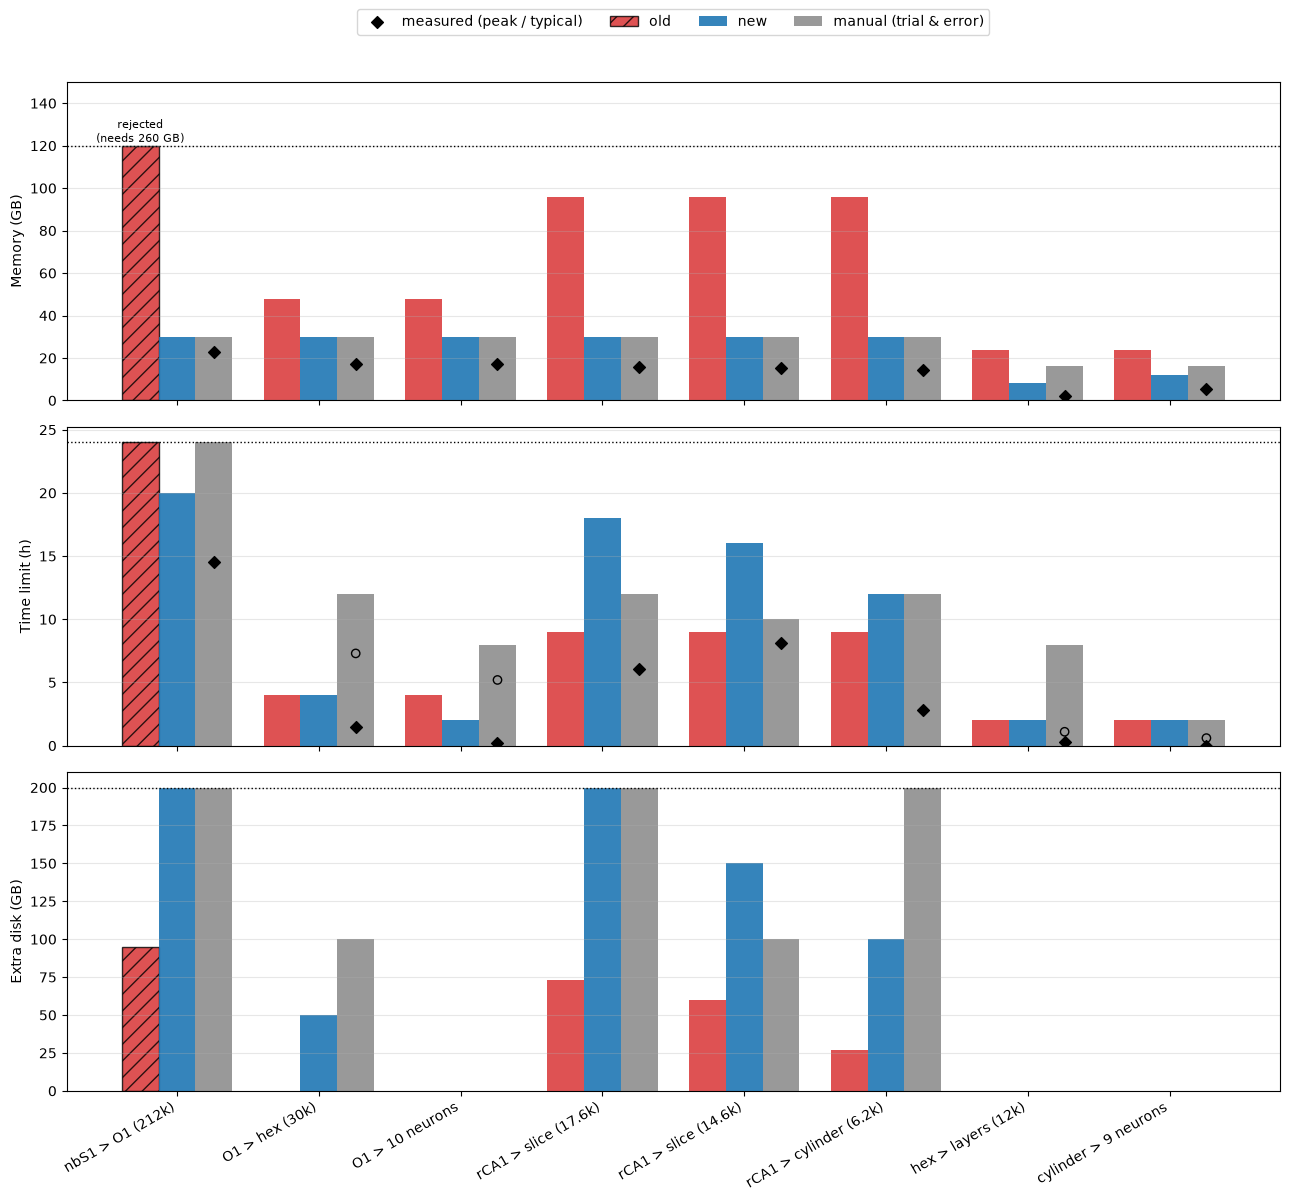

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
x = np.arange(len(BENCHMARKS))
w = 0.26
panels = [
    ("memory", "Memory (GB)", "manual_memory", "peak_gb"),
    ("time_h", "Time limit (h)", "manual_time_h", "typical_h"),
    ("disk_gb", "Extra disk (GB)", "manual_disk_gb", None),
]
for ax, (key, ylabel, manual_col, measured_col) in zip(axes, panels):
    old = BENCHMARKS[f"old_{key}"].to_numpy(dtype=float)
    new = BENCHMARKS[f"new_{key}"].to_numpy(dtype=float)
    rejected = BENCHMARKS["old_rejected"].to_numpy()
    if key == "memory":  # show rejected requests at the largest machine, annotated with the requirement
        old_plot = np.where(rejected, estimator.MAX_MEMORY_GB, old)
    else:
        old_plot = old
    bars = ax.bar(x - w, old_plot, w, label="old", color="tab:red", alpha=0.8)
    ax.bar(x, new, w, label="new", color="tab:blue", alpha=0.9)
    ax.bar(x + w, BENCHMARKS[manual_col], w, label="manual (trial & error)", color="0.6")
    for bar, rej in zip(bars, rejected):
        if rej:
            bar.set_hatch("//")
            bar.set_edgecolor("k")
    if key == "memory":
        for xi, (rej, row) in enumerate(zip(rejected, BENCHMARKS.itertuples())):
            if rej:
                need = 1 + 55e-6 * old_input_neurons(PARENTS[row.parent])
                ax.annotate(f"rejected\n(needs {need:.0f} GB)", (xi - w, estimator.MAX_MEMORY_GB), ha="center", va="bottom", fontsize=8)
        ax.axhline(estimator.MAX_MEMORY_GB, color="k", ls=":", lw=1)
        ax.set_ylim(0, 150)
    if key == "time_h":
        ax.axhline(estimator.MAX_TIME_LIMIT_H, color="k", ls=":", lw=1)
    if key == "disk_gb":
        ax.axhline(estimator.EXTRA_DISK_SPACE_LIMIT_GB, color="k", ls=":", lw=1)
    if measured_col:
        ax.scatter(x + w, BENCHMARKS[measured_col], marker="D", color="k", zorder=3, label="measured (peak / typical)")
    if key == "time_h":
        ax.scatter(x + w, BENCHMARKS["slow_h"], marker="o", facecolor="none", edgecolor="k", zorder=3, label="measured, slow split")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.25))
axes[-1].set_xticks(x, BENCHMARKS["label"], rotation=30, ha="right")
fig.tight_layout()
plt.show()

### Benchmark cases without virtual and external populations
The same extractions with `do_virtual=False` and `create_external=False`. The old formulas only had `do_virtual`, which left out all virtual populations, externalized ones included. The new ones leave out afferent virtual populations with `do_virtual=False` and externalized ones with `create_external=False`, so with both off they count the biophysical neurons and synapses only, like the old ones. Light bars: the new estimate with both options on, as in the benchmark runs. There are no measurements for this configuration (all benchmark runs used both options).

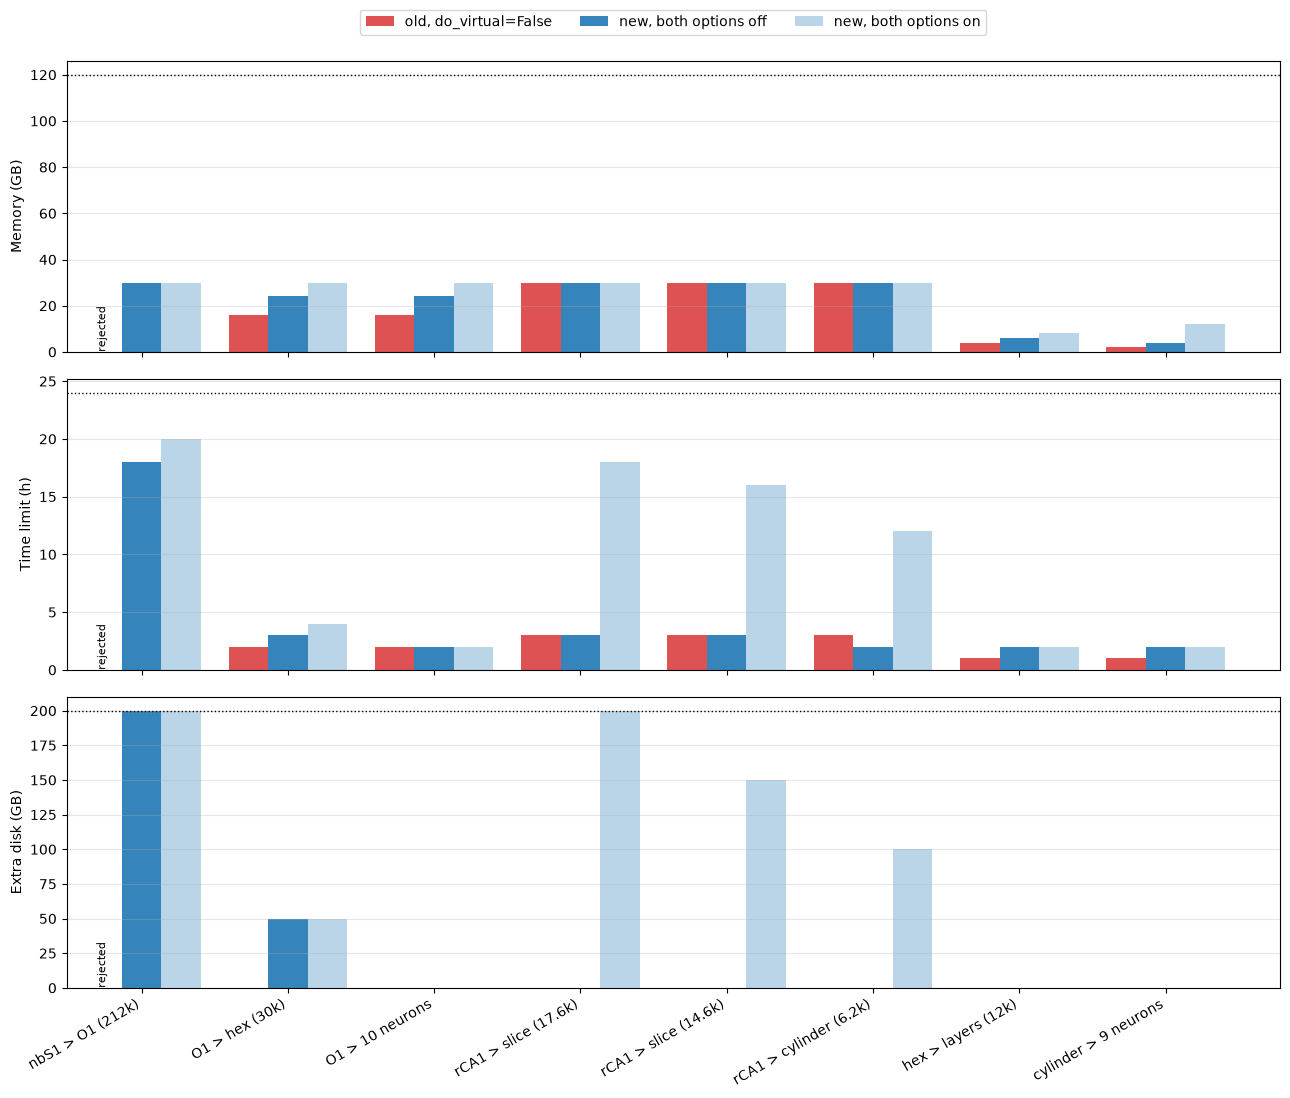

,old_off_memory,new_off_memory,new_on_memory,old_off_time_h,new_off_time_h,new_on_time_h,old_off_disk_gb,new_off_disk_gb,new_on_disk_gb
label,,,,,,,,,
nbS1 > O1 (212k),NaN,30.0,30.0,NaN,18.0,20.0,NaN,200.0,200.0
O1 > hex (30k),16.0,24.0,30.0,2.0,3.0,4.0,0.0,50.0,50.0
O1 > 10 neurons,16.0,24.0,30.0,2.0,2.0,2.0,0.0,0.0,0.0
rCA1 > slice (17.6k),30.0,30.0,30.0,3.0,3.0,18.0,0.0,0.0,200.0
rCA1 > slice (14.6k),30.0,30.0,30.0,3.0,3.0,16.0,0.0,0.0,150.0
rCA1 > cylinder (6.2k),30.0,30.0,30.0,3.0,2.0,12.0,0.0,0.0,100.0
hex > layers (12k),4.0,6.0,8.0,1.0,2.0,2.0,0.0,0.0,0.0
cylinder > 9 neurons,2.0,4.0,12.0,1.0,2.0,2.0,0.0,0.0,0.0


In [5]:
BIO_ONLY = BENCHMARKS[["label", "parent", "extracted"]].copy()
options = {
    "old_off": (estimate_old, {"do_virtual": False}),
    "new_off": (estimate_new, {"do_virtual": False, "create_external": False}),
    "new_on": (estimate_new, {"do_virtual": True, "create_external": True}),
}
for name, (fn, kwargs) in options.items():
    est = pd.DataFrame([fn(PARENTS[r.parent], r.extracted, **kwargs) for r in BIO_ONLY.itertuples()])
    est.loc[est.rejected, ["memory", "time_h", "disk_gb"]] = np.nan  # a rejected estimate allocates nothing
    BIO_ONLY = BIO_ONLY.join(est[["memory", "time_h", "disk_gb", "rejected"]].add_prefix(f"{name}_"))

fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
x = np.arange(len(BIO_ONLY))
w = 0.27
panels = [
    ("memory", "Memory (GB)", estimator.MAX_MEMORY_GB),
    ("time_h", "Time limit (h)", estimator.MAX_TIME_LIMIT_H),
    ("disk_gb", "Extra disk (GB)", estimator.EXTRA_DISK_SPACE_LIMIT_GB),
]
for ax, (key, ylabel, limit) in zip(axes, panels):
    ax.bar(x - w, BIO_ONLY[f"old_off_{key}"], w, label="old, do_virtual=False", color="tab:red", alpha=0.8)
    ax.bar(x, BIO_ONLY[f"new_off_{key}"], w, label="new, both options off", color="tab:blue", alpha=0.9)
    ax.bar(x + w, BIO_ONLY[f"new_on_{key}"], w, label="new, both options on", color="tab:blue", alpha=0.3)
    for xi, row in enumerate(BIO_ONLY.itertuples()):  # mark rejected estimates
        for dx, name in [(-w, "old_off"), (0, "new_off"), (w, "new_on")]:
            if getattr(row, f"{name}_rejected"):
                ax.text(xi + dx, 0, "rejected", rotation=90, ha="center", va="bottom", fontsize=8)
    ax.axhline(limit, color="k", ls=":", lw=1)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.2))
axes[-1].set_xticks(x, BIO_ONLY["label"], rotation=30, ha="right")
fig.tight_layout()
plt.show()

BIO_ONLY.set_index("label")[[f"{n}_{k}" for k in ["memory", "time_h", "disk_gb"] for n in options]]

## Sweep over the extracted size
Requested resources for extracting `n` neurons from a parent circuit (the estimate only uses the count). Black markers are the benchmark runs of the same parent. Gaps: the estimate is rejected. The new memory estimate is flat because it saturates with the parent size.

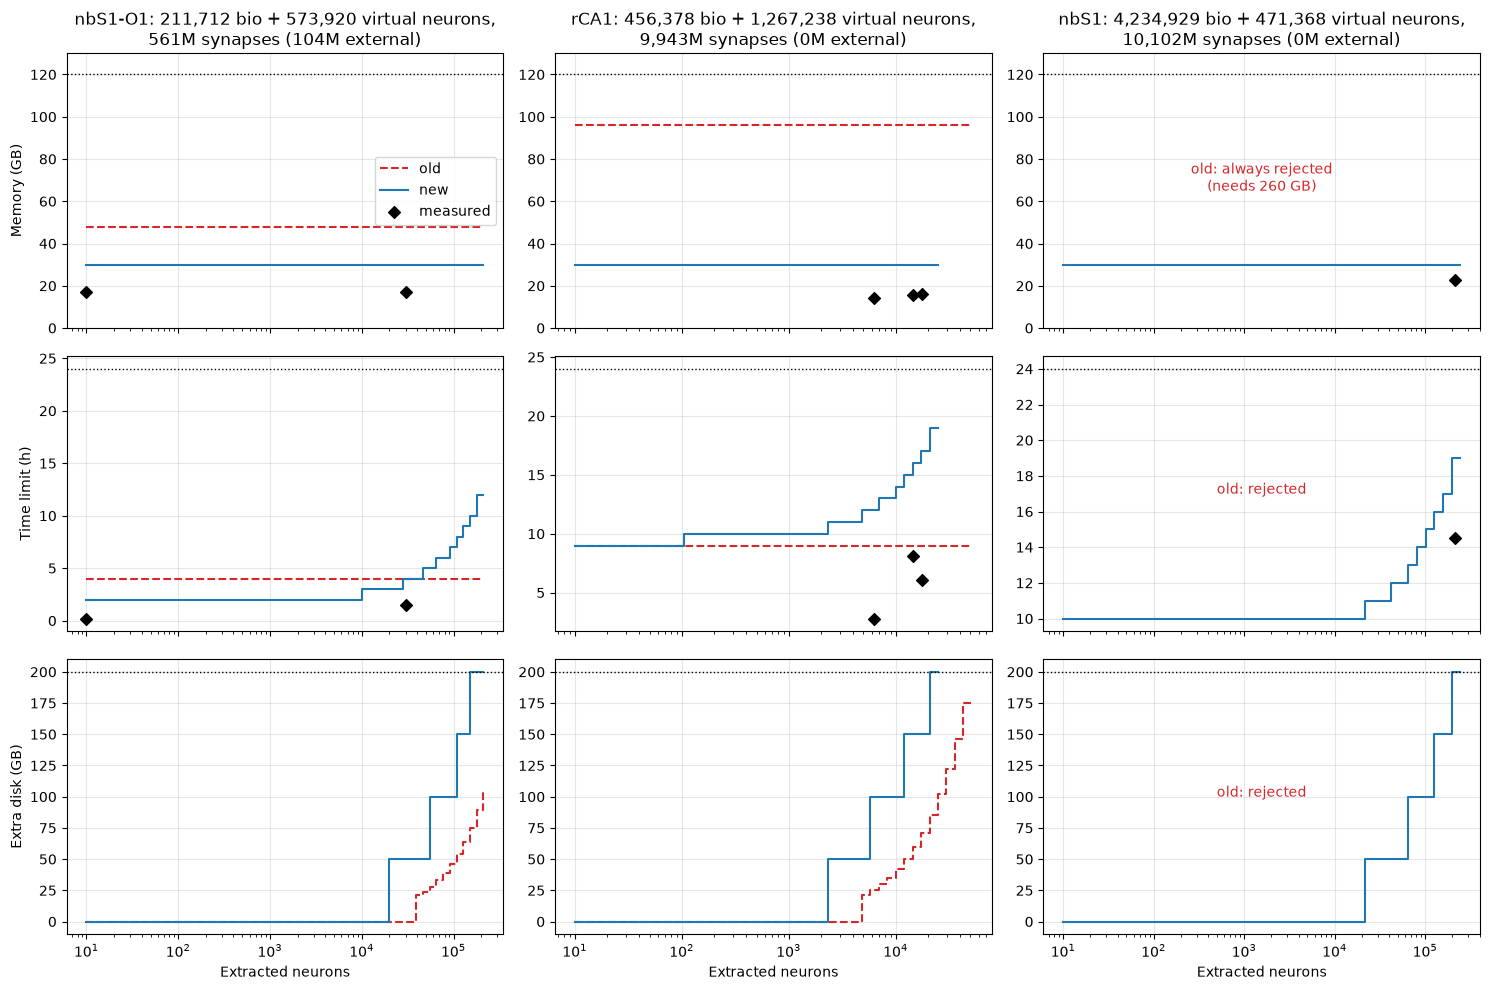

In [6]:
def sweep(parent_name, n_points=60):
    parent = PARENTS[parent_name]
    n = np.unique(np.geomspace(10, parent.n_bio, n_points).astype(int))
    old = pd.DataFrame([estimate_old(parent, k) for k in n])
    new = pd.DataFrame([estimate_new(parent, k) for k in n])
    return n, old, new


fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex="col")
for col, parent_name in enumerate(["nbS1-O1", "rCA1", "nbS1"]):
    n, old, new = sweep(parent_name)
    bench = BENCHMARKS[BENCHMARKS.parent == parent_name]
    for row, (key, ylabel, measured_col) in enumerate([("memory", "Memory (GB)", "peak_gb"), ("time_h", "Time limit (h)", "typical_h"), ("disk_gb", "Extra disk (GB)", None)]):
        ax = axes[row, col]
        old_values = old[key].where(~old.rejected)  # a rejected estimate allocates nothing
        ax.plot(n, old_values, color="tab:red", ls="--", label="old", drawstyle="steps-post")
        ax.plot(n, new[key], color="tab:blue", label="new", drawstyle="steps-post")
        if measured_col:
            ax.scatter(bench.extracted, bench[measured_col], marker="D", color="k", zorder=3, label="measured")
        if key == "memory":
            ax.axhline(estimator.MAX_MEMORY_GB, color="k", ls=":", lw=1)
            ax.set_ylim(0, 130)
            if old.rejected.all():
                ax.text(0.5, 0.5, "old: always rejected\n(needs {:.0f} GB)".format(1 + 55e-6 * old_input_neurons(PARENTS[parent_name])), transform=ax.transAxes, ha="center", color="tab:red")
        if old.rejected.all() and key != "memory":
            ax.text(0.5, 0.5, "old: rejected", transform=ax.transAxes, ha="center", color="tab:red")
        if key == "time_h":
            ax.axhline(estimator.MAX_TIME_LIMIT_H, color="k", ls=":", lw=1)
        if key == "disk_gb":
            ax.axhline(estimator.EXTRA_DISK_SPACE_LIMIT_GB, color="k", ls=":", lw=1)
        ax.set_xscale("log")
        ax.grid(alpha=0.3)
        if col == 0:
            ax.set_ylabel(ylabel)
        if row == 0:
            p = PARENTS[parent_name]
            ax.set_title(
                f"{parent_name}: {p.n_bio:,} bio + {p.n_virtual + p.n_external:,} virtual neurons,\n"
                f"{(p.s_bio + p.s_virtual + p.s_external) / 1e6:,.0f}M synapses ({p.s_external / 1e6:,.0f}M external)"
            )
        if row == 2:
            ax.set_xlabel("Extracted neurons")
axes[0, 0].legend()
fig.tight_layout()
plt.show()

## Sweep over the input circuit size
Requested resources for parent circuits of increasing size, when extracting a fixed percentage of their biophysical neurons. The parents are scaled versions of two benchmark circuits, keeping their composition per biophysical neuron (virtual neurons, biophysical and virtual synapses). Both are root circuits, without externalized populations:
- **nbS1-like**: few virtual neurons (0.11 per biophysical neuron), about 2,400 synapses per biophysical neuron.
- **rCA1-like**: many virtual neurons (2.8 per biophysical neuron), about 21,800 synapses per biophysical neuron, mostly from virtual neurons.

Solid lines: new formulas, dashed lines: old formulas, one color per extracted percentage. Gaps: the estimate is rejected. Dotted vertical lines: sizes of the benchmark parents. Dotted horizontal lines: the limits (largest machine, 24 h time limit, 200 GB extra disk). Memory depends only on the parent (old: its neurons, new: its synapses), so the memory lines of all percentages coincide; they only end at different sizes, where the extraction gets rejected for disk.

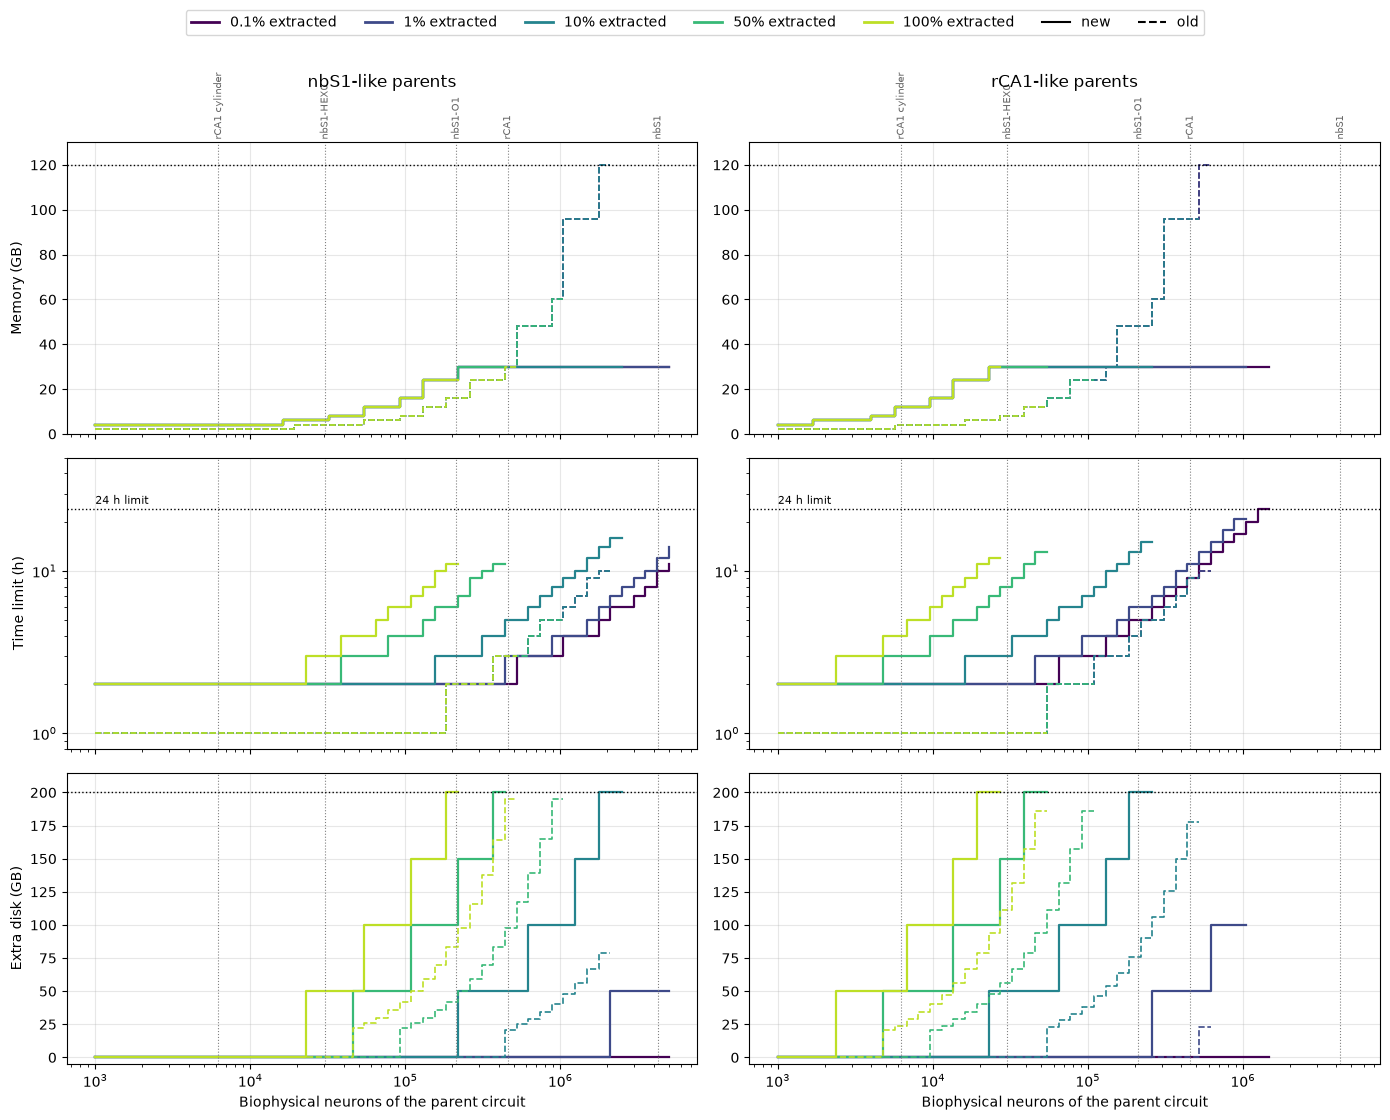

In [7]:
TEMPLATES = {"nbS1-like": "nbS1", "rCA1-like": "rCA1"}
PERCENTAGES = [0.1, 1, 10, 50, 100]
N_BIO = np.unique(np.geomspace(1_000, 5_000_000, 50).astype(int))


def scaled_parent(template, nbio):
    """Parent with nbio biophysical neurons and the composition of the template parent."""
    t = PARENTS[template]
    f = nbio / t.n_bio
    return Parent(nbio, *(round(v * f) for v in t[1:]))


rows = []
for label, template in TEMPLATES.items():
    for pct in PERCENTAGES:
        for nbio in N_BIO:
            parent = scaled_parent(template, nbio)
            extracted = max(1, round(nbio * pct / 100))
            for name, fn in [("old", estimate_old), ("new", estimate_new)]:
                est = fn(parent, extracted)
                rows.append({"template": label, "pct": pct, "nbio": nbio, "formula": name, **{k: est[k] for k in ["memory", "time_h", "disk_gb", "rejected"]}})
INPUT_SWEEP = pd.DataFrame(rows)
for key in ["memory", "time_h", "disk_gb"]:  # a rejected estimate allocates nothing
    INPUT_SWEEP.loc[INPUT_SWEEP.rejected, key] = np.nan

colors = dict(zip(PERCENTAGES, plt.cm.viridis(np.linspace(0, 0.9, len(PERCENTAGES)))))
fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=True)
for col, (label, template) in enumerate(TEMPLATES.items()):
    data = INPUT_SWEEP[INPUT_SWEEP.template == label]
    for row, (key, ylabel) in enumerate([("memory", "Memory (GB)"), ("time_h", "Time limit (h)"), ("disk_gb", "Extra disk (GB)")]):
        ax = axes[row, col]
        for pct in PERCENTAGES:
            for name, ls in [("old", "--"), ("new", "-")]:
                d = data[(data.pct == pct) & (data.formula == name)]
                ax.plot(d.nbio, d[key], ls=ls, color=colors[pct], drawstyle="steps-post", lw=1.6 if name == "new" else 1.2)
        for parent_name, p in PARENTS.items():
            ax.axvline(p.n_bio, color="0.5", ls=":", lw=0.8)
            if row == 0:
                ax.text(p.n_bio, 1.01, parent_name, transform=ax.get_xaxis_transform(), rotation=90, fontsize=7, ha="center", va="bottom", color="0.4")
        if key == "memory":
            ax.axhline(estimator.MAX_MEMORY_GB, color="k", ls=":", lw=1)
            ax.set_ylim(0, 130)
        if key == "time_h":
            ax.set_yscale("log")
            ax.axhline(estimator.MAX_TIME_LIMIT_H, color="k", ls=":", lw=1)
            ax.set_ylim(0.8, 50)
            ax.text(N_BIO[0], estimator.MAX_TIME_LIMIT_H * 1.08, f"{estimator.MAX_TIME_LIMIT_H} h limit", fontsize=8)
        if key == "disk_gb":
            ax.axhline(estimator.EXTRA_DISK_SPACE_LIMIT_GB, color="k", ls=":", lw=1)
            ax.set_ylim(-5, 215)
        ax.set_xscale("log")
        ax.grid(alpha=0.3)
        if col == 0:
            ax.set_ylabel(ylabel)
        if row == 0:
            ax.set_title(f"{label} parents", pad=40)
        if row == 2:
            ax.set_xlabel("Biophysical neurons of the parent circuit")
handles = [plt.Line2D([], [], color=colors[p], lw=2, label=f"{p:g}% extracted") for p in PERCENTAGES]
handles += [plt.Line2D([], [], color="k", ls="-", label="new"), plt.Line2D([], [], color="k", ls="--", label="old")]
fig.legend(handles=handles, ncol=len(handles), loc="upper center", bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

### Largest launchable extraction
Largest parent (biophysical neurons) for which an extraction of each percentage is still accepted, i.e. not rejected for memory, time or disk.

In [8]:
accepted = INPUT_SWEEP[~INPUT_SWEEP.rejected]
largest = accepted.groupby(["template", "pct", "formula"]).nbio.max().unstack("formula")
largest = largest.reindex(pd.MultiIndex.from_product([list(TEMPLATES), PERCENTAGES], names=["template", "pct"]))
largest.map(lambda v: "none" if pd.isna(v) else f"{v:,.0f}")

formula                new        old
template  pct                        
nbS1-like 0.1    5,000,000  1,762,117
          1.0    5,000,000  1,762,117
          10.0   2,096,641  1,762,117
          50.0     368,665    879,180
          100.0    183,939    438,653
rCA1-like 0.1    1,244,676    521,928
          1.0      879,180    521,928
          10.0     218,859    438,653
          50.0      45,789     91,773
          100.0     22,845     45,789

## Summary table
Allocations for the benchmark runs (memory in GB, time limit in h, extra disk in GB; NaN: rejected).

In [9]:
summary = BENCHMARKS.set_index("label")[
    ["old_memory", "new_memory", "manual_memory", "peak_gb", "old_time_h", "new_time_h", "manual_time_h", "typical_h", "old_disk_gb", "new_disk_gb", "manual_disk_gb"]
]
summary

,old_memory,new_memory,manual_memory,peak_gb,old_time_h,new_time_h,manual_time_h,typical_h,old_disk_gb,new_disk_gb,manual_disk_gb
label,,,,,,,,,,,
nbS1 > O1 (212k),NaN,30,30,22.9,24,20,24,14.5,95,200,200
O1 > hex (30k),48.0,30,30,17.0,4,4,12,1.5,0,50,100
O1 > 10 neurons,48.0,30,30,17.0,4,2,8,0.2,0,0,0
rCA1 > slice (17.6k),96.0,30,30,15.9,9,18,12,6.1,73,200,200
rCA1 > slice (14.6k),96.0,30,30,15.4,9,16,10,8.1,60,150,100
rCA1 > cylinder (6.2k),96.0,30,30,14.2,9,12,12,2.8,27,100,200
hex > layers (12k),24.0,8,16,2.3,2,2,8,0.3,0,0,0
cylinder > 9 neurons,24.0,12,16,5.4,2,2,2,0.0,0,0,0
